In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "vscode"

df = pd.read_csv(r"D:\Auspify Internship\Task 1\Netflix_Cleaned.csv")   # use your Task 1 output file name
print(df.shape)
print(df.columns.tolist())

(8786, 14)
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'year_added', 'month_added', 'duration_value', 'duration_unit']


In [16]:
print(df['rating'].unique())
print(df['rating'].nunique())
print(df['rating'].isnull().sum())
print(df['rating'].value_counts())

['PG-13' 'TV-MA' 'TV-PG' 'TV-14' 'TV-Y7' 'TV-Y' 'PG' 'TV-G' 'R' 'G'
 'NC-17' 'Not Rated' 'TV-Y7-FV']
13
0
rating
TV-MA        3204
TV-14        2155
TV-PG         861
R             798
PG-13         490
TV-Y7         333
TV-Y          306
PG            287
TV-G          220
Not Rated      82
G              41
TV-Y7-FV        6
NC-17           3
Name: count, dtype: int64


In [17]:
def audience(r):
    if r in ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G"]:
        return "Kids"
    elif r in ["PG", "TV-PG", "PG-13", "TV-14"]:
        return "Teens"
    elif r in ["R", "TV-MA", "NC-17"]:
        return "Adults"
    return "Other"   # Not Rated

df['audience'] = df['rating'].apply(audience)
print(df['audience'].value_counts())

audience
Adults    4005
Teens     3793
Kids       906
Other       82
Name: count, dtype: int64


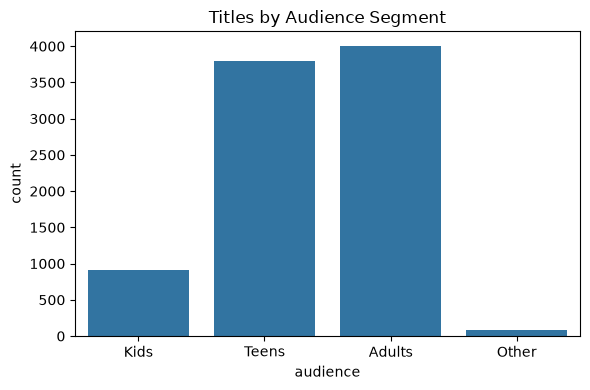

In [18]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='audience', order=['Kids', 'Teens', 'Adults', 'Other'])
plt.title("Titles by Audience Segment")
plt.tight_layout()
plt.show()

In [19]:
print(df.columns.tolist())
print(df['listed_in'].head(10))

['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'year_added', 'month_added', 'duration_value', 'duration_unit', 'audience']
0                                        Documentaries
1    Crime TV Shows, International TV Shows, TV Act...
2                   TV Dramas, TV Horror, TV Mysteries
3                   Children & Family Movies, Comedies
4     Dramas, Independent Movies, International Movies
5                         British TV Shows, Reality TV
6                                     Comedies, Dramas
7    Children & Family Movies, Comedies, Music & Mu...
8                         Dramas, International Movies
9           Children & Family Movies, Music & Musicals
Name: listed_in, dtype: object


In [20]:
genres = df[['show_id', 'type', 'rating', 'audience', 'listed_in']].copy()
genres['listed_in'] = genres['listed_in'].str.split(',')
genres = genres.explode('listed_in')
genres['listed_in'] = genres['listed_in'].str.strip()

print(genres.shape)
print(genres['listed_in'].nunique())

(19284, 5)
42


listed_in
International Movies        2751
Dramas                      2423
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


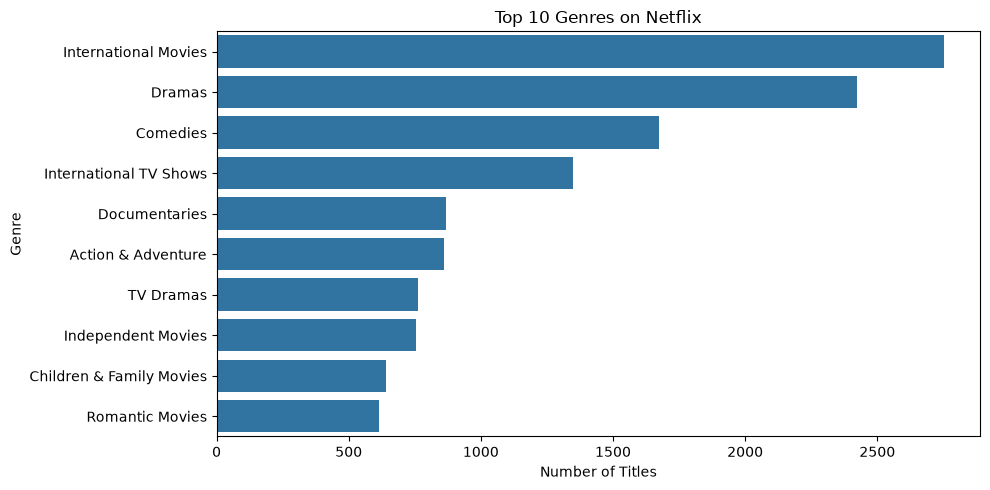

In [21]:
top_genres = genres['listed_in'].value_counts().head(10)
print(top_genres)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [22]:
rating_type = pd.crosstab(df['rating'], df['type'])
print(rating_type)

type       Movie  TV Show
rating                   
G             41        0
NC-17          3        0
Not Rated     78        4
PG           287        0
PG-13        490        0
R            796        2
TV-14       1426      729
TV-G         126       94
TV-MA       2061     1143
TV-PG        540      321
TV-Y         131      175
TV-Y7        139      194
TV-Y7-FV       5        1


In [23]:
rating_type_pct = pd.crosstab(df['rating'], df['type'], normalize='columns') * 100
print(rating_type_pct.round(1))

type       Movie  TV Show
rating                   
G            0.7      0.0
NC-17        0.0      0.0
Not Rated    1.3      0.2
PG           4.7      0.0
PG-13        8.0      0.0
R           13.0      0.1
TV-14       23.3     27.4
TV-G         2.1      3.5
TV-MA       33.7     42.9
TV-PG        8.8     12.1
TV-Y         2.1      6.6
TV-Y7        2.3      7.3
TV-Y7-FV     0.1      0.0


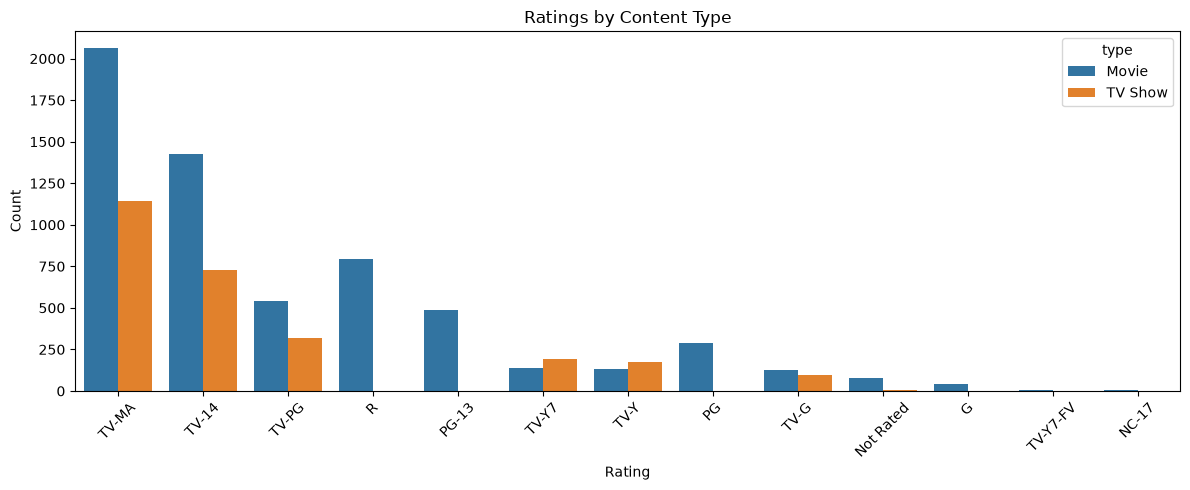

In [24]:
order = df['rating'].value_counts().index

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='rating', hue='type', order=order)
plt.title("Ratings by Content Type")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

audience  Adults  Kids  Other  Teens
type                                
Movie       46.7   7.2    1.3   44.8
TV Show     43.0  17.4    0.2   39.4


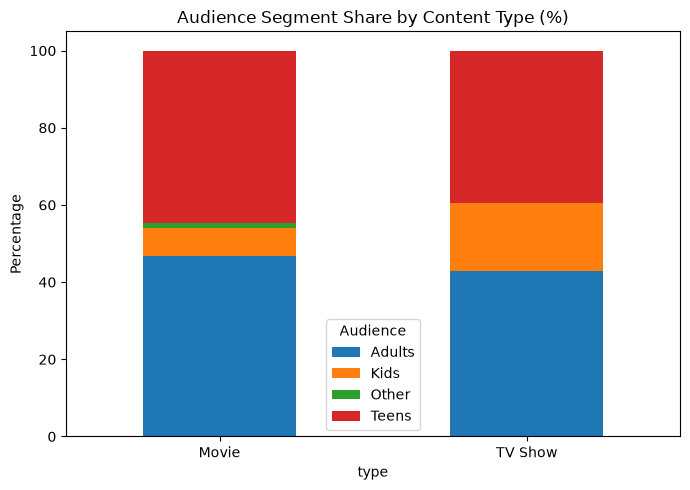

In [25]:
audience_type = pd.crosstab(df['type'], df['audience'], normalize='index') * 100
print(audience_type.round(1))

audience_type.plot(kind='bar', stacked=True, figsize=(7, 5))
plt.title("Audience Segment Share by Content Type (%)")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Audience")
plt.tight_layout()
plt.show()

In [26]:
%pip install plotly nbformat


Note: you may need to restart the kernel to use updated packages.


In [32]:
order = list(df['rating'].value_counts().index)

fig1 = px.histogram(df, x='rating', color='type', barmode='group',
                   category_orders={'rating': order},
                   title="Ratings by Content Type")
fig1.update_layout(xaxis_title="Rating", yaxis_title="Count")
fig1.show()

In [28]:
top10 = list(genres['listed_in'].value_counts().head(10).index)
g = genres[genres['listed_in'].isin(top10)]

fig2 = px.histogram(g, y='listed_in', color='type', barmode='group',
                    category_orders={'listed_in': top10},
                    title="Top 10 Genres by Content Type")
fig2.update_yaxes(autorange='reversed')
fig2.update_layout(xaxis_title="Number of Titles", yaxis_title="Genre")
fig2.show()

In [29]:
sun = df.groupby(['type', 'audience', 'rating']).size().reset_index(name='count')

fig3 = px.sunburst(sun, path=['type', 'audience', 'rating'], values='count',
                   title="Content Breakdown: Type → Audience → Rating")
fig3.show()

In [30]:
ga = pd.crosstab(g['listed_in'], g['audience'])[['Kids', 'Teens', 'Adults', 'Other']]
ga = ga.loc[top10]

fig4 = px.imshow(ga, text_auto=True, aspect='auto', color_continuous_scale='Blues',
                 title="Top Genres by Audience Segment")
fig4.show()

In [33]:
fig1.write_html("ratings_by_type.html")
fig2.write_html("genres_by_type.html")
fig3.write_html("sunburst_breakdown.html")
fig4.write_html("genre_audience_heatmap.html")